<a href="https://www.kaggle.com/code/yildirimemirhan/wbc-analyzer-quickstart?scriptVersionId=358813774" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# WBC Analyzer: white blood cell classification quickstart

Classifies a peripheral blood smear crop into one of five leukocyte types:
**Basophil, Eosinophil, Lymphocyte, Monocyte, Neutrophil**.

The model is a DenseNet121 backbone with a CBAM-style `WBCAttentionBlock` and a
learnable `MedSwish` activation, fed by a deterministic *Medical Enhanced Filter*
(percentile clip + LAB CLAHE + bilateral + edge-weighted sharpen). It has a 5-class
head (`main_out`) and an auxiliary Neutrophil-vs-Lymphocyte sigmoid (`aux_binary_out`).

| Split | Distribution | n | Accuracy | Weighted F1 |
| :-- | :-- | --: | --: | --: |
| TestA | in-distribution (professional lab camera) | 4,339 | 98.53% | 0.9854 |
| TestB | out-of-distribution (smartphone, Lymphocyte + Neutrophil only) | 2,119 | 89.05% | 0.9111 |
| Combined | | 6,458 | 95.42% | 0.9554 |

These are the paper's figures, which use the full inference stack (Reinhard colour
normalisation, Neutrophil/Lymphocyte routing on TestB, 8x test-time augmentation). Measured with
this notebook's code on the full splits, single pass, no TTA:

| Pipeline | TestA | TestB |
| :-- | --: | --: |
| plain (`medical_enhanced` only) | 97.76% | 56.11% |
| + Reinhard + TestB routing | 98.32% | 88.49% |

Section 7 reproduces both rows. The gap on TestB is the domain-shift problem the paper addresses.

**What this notebook does**

1. Loads the model (with a fix for models saved by a newer Keras than the one installed).
2. Runs it on five bundled example images, no dataset needed.
3. Shows what the preprocessing does.
4. Explains predictions with Grad-CAM.
5. Classifies your own folder of images and writes a CSV.
6. Optionally evaluates on Raabin-WBC TestA/TestB if the dataset is attached.

> **Research use only.** Not a medical device and not for clinical decisions.

**Setup on Kaggle:** *Add Input* and attach this model. Optionally also attach the
[Raabin-WBC dataset](https://raabindata.com/free-data/) for section 7. Source code:
[github.com/yildirimemirhan/wbc-analyzer](https://github.com/yildirimemirhan/wbc-analyzer).

## 1. Setup and model

In [1]:
import base64
import glob
import json
import os
import tempfile
import zipfile
from pathlib import Path

import cv2
import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

CLASS_NAMES = ["Basophil", "Eosinophil", "Lymphocyte", "Monocyte", "Neutrophil"]
IMG_SIZE = 224
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
MAIN_IDX = {name: i for i, name in enumerate(CLASS_NAMES)}

print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| OpenCV", cv2.__version__)
print("GPU:", tf.config.list_physical_devices("GPU") or "none (CPU is fine for this notebook)")

TensorFlow 2.20.0 | Keras 3.13.2 | OpenCV 4.14.0
GPU: none (CPU is fine for this notebook)


2026-10-15 21:36:54.022815: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


The three cells below are verbatim copies of `src/custom_layers.py`, `src/custom_losses.py` and `src/preprocessing.py`. They must be defined before the model can be deserialised.

In [2]:
# ===== src/custom_layers.py (verbatim copy) =====
import tensorflow as tf

keras = tf.keras
layers = keras.layers


@tf.keras.utils.register_keras_serializable(package="WBC")
class MedSwish(layers.Layer):
    """Swish-like activation with trainable slope and enhancement terms."""

    def __init__(self, alpha=0.1, beta=1.0, trainable_params=True, **kwargs):
        super(MedSwish, self).__init__(**kwargs)
        self.initial_alpha = alpha
        self.initial_beta = beta
        self.trainable_params = trainable_params

    def build(self, input_shape):
        if self.trainable_params:
            self.alpha = self.add_weight(
                name="alpha",
                shape=(1,),
                initializer=tf.keras.initializers.Constant(self.initial_alpha),
                trainable=True,
            )
            self.beta = self.add_weight(
                name="beta",
                shape=(1,),
                initializer=tf.keras.initializers.Constant(self.initial_beta),
                trainable=True,
            )
        else:
            self.alpha = tf.constant(self.initial_alpha, dtype=tf.float32)
            self.beta = tf.constant(self.initial_beta, dtype=tf.float32)
        super(MedSwish, self).build(input_shape)

    def call(self, x):
        x = tf.cast(x, dtype=self.compute_dtype)
        # Base swish branch + bounded enhancement branch.
        swish_part = x * tf.nn.sigmoid(self.beta * x)
        enhancement = 1.0 + self.alpha * tf.nn.tanh(x)
        return swish_part * enhancement

    def get_config(self):
        config = super(MedSwish, self).get_config()
        config.update(
            {
                "alpha": float(self.initial_alpha),
                "beta": float(self.initial_beta),
                "trainable_params": self.trainable_params,
            }
        )
        return config


@tf.keras.utils.register_keras_serializable(package="WBC")
class WBCAttentionBlock(layers.Layer):
    """CBAM-style attention block with channel then spatial refinement."""

    def __init__(self, reduction_ratio=16, **kwargs):
        super(WBCAttentionBlock, self).__init__(**kwargs)
        self.reduction_ratio = reduction_ratio

    def build(self, input_shape):
        channels = input_shape[-1]

        self.channel_dense1 = layers.Dense(
            channels // self.reduction_ratio,
            activation="relu",
            kernel_initializer="he_normal",
            use_bias=True,
        )
        self.channel_dense2 = layers.Dense(
            channels, kernel_initializer="he_normal", use_bias=True
        )

        self.spatial_conv = layers.Conv2D(
            1,
            kernel_size=7,
            padding="same",
            activation="sigmoid",
            kernel_initializer="he_normal",
            use_bias=True,
        )

        super(WBCAttentionBlock, self).build(input_shape)

    def channel_attention(self, x):
        # Pool across spatial axes to summarize each channel.
        avg_pool = tf.reduce_mean(x, axis=[1, 2], keepdims=True)
        max_pool = tf.reduce_max(x, axis=[1, 2], keepdims=True)

        avg_pool = tf.reshape(avg_pool, [-1, avg_pool.shape[-1]])
        max_pool = tf.reshape(max_pool, [-1, max_pool.shape[-1]])

        avg_out = self.channel_dense2(self.channel_dense1(avg_pool))
        max_out = self.channel_dense2(self.channel_dense1(max_pool))

        channel_att = tf.nn.sigmoid(avg_out + max_out)
        channel_att = tf.reshape(channel_att, [-1, 1, 1, channel_att.shape[-1]])

        channel_att = tf.cast(channel_att, x.dtype)
        return x * channel_att

    def spatial_attention(self, x):
        # Pool across channels to highlight informative spatial locations.
        avg_pool = tf.reduce_mean(x, axis=-1, keepdims=True)
        max_pool = tf.reduce_max(x, axis=-1, keepdims=True)
        concat = tf.concat([avg_pool, max_pool], axis=-1)

        spatial_att = self.spatial_conv(concat)

        spatial_att = tf.cast(spatial_att, x.dtype)
        return x * spatial_att

    def call(self, x):
        # Sequential channel->spatial attention keeps behavior deterministic.
        x = self.channel_attention(x)
        x = self.spatial_attention(x)
        return x

    def get_config(self):
        config = super(WBCAttentionBlock, self).get_config()
        config.update({"reduction_ratio": self.reduction_ratio})
        return config

In [3]:
# ===== src/custom_losses.py (verbatim copy) =====
import tensorflow as tf
import keras


@tf.keras.utils.register_keras_serializable(package="WBC")
class WBCFocalLoss(keras.losses.Loss):
    """
    WBC focal loss.

    Formula: FL(p_t) = -α_t * (1 - p_t)^γ * log(p_t)
    """

    def __init__(
        self,
        gamma=2.0,
        alpha=0.25,
        class_weights=None,
        label_smoothing=0.1,
        name="wbc_focal_loss",
        **kwargs
    ):
        super(WBCFocalLoss, self).__init__(name=name, **kwargs)
        self.gamma = gamma
        self.alpha = alpha
        self.label_smoothing = label_smoothing

        if class_weights is None:
            self.class_weights = tf.constant(
                [2.0, 1.2, 1.0, 1.3, 1.0], dtype=tf.float32
            )
        else:
            self.class_weights = tf.constant(class_weights, dtype=tf.float32)

    def call(self, y_true, y_pred):
        """Compute class-weighted focal loss with optional label smoothing."""
        num_classes = tf.shape(y_true)[-1]
        y_true_smooth = y_true * (
            1.0 - self.label_smoothing
        ) + self.label_smoothing / tf.cast(num_classes, tf.float32)

        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)

        cross_entropy = -y_true_smooth * tf.math.log(y_pred)

        p_t = tf.reduce_sum(y_true * y_pred, axis=-1, keepdims=True)
        focal_weight = tf.pow(1.0 - p_t, self.gamma)

        weights = tf.reduce_sum(y_true * self.class_weights, axis=-1, keepdims=True)

        focal_loss = self.alpha * focal_weight * cross_entropy * weights

        return tf.reduce_mean(tf.reduce_sum(focal_loss, axis=-1))

    def get_config(self):
        """Return serializable layer configuration."""
        config = super(WBCFocalLoss, self).get_config()
        config.update(
            {
                "gamma": self.gamma,
                "alpha": self.alpha,
                "label_smoothing": self.label_smoothing,
            }
        )
        return config

In [4]:
# ===== src/preprocessing.py (verbatim copy) =====
import cv2
import numpy as np
from typing import Optional, Tuple


def _to_uint8(image: np.ndarray) -> np.ndarray:
    """Normalize any float or uint8 image to uint8 [0, 255]."""
    if image.dtype == np.uint8:
        return image.copy()
    if np.max(image) <= 1.0:
        return np.clip(image * 255.0, 0, 255).astype(np.uint8)
    return np.clip(image, 0, 255).astype(np.uint8)


class PreprocessingFilters:

    @staticmethod
    def original(image: np.ndarray) -> np.ndarray:
        """Baseline: scale to float32 [0, 1] with no spatial processing."""
        return image.astype(np.float32) / 255.0

    @staticmethod
    def clahe(
        image: np.ndarray,
        clip_limit: float = 2.0,
        tile_size: int = 8,
    ) -> np.ndarray:
        """CLAHE in LAB space — boosts local contrast without hue shift."""
        lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
        l, a, b = cv2.split(lab)
        clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=(tile_size, tile_size))
        l = clahe.apply(l)
        lab = cv2.merge([l, a, b])
        result = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)
        return result.astype(np.float32) / 255.0

    @staticmethod
    def gaussian_sharpen(
        image: np.ndarray,
        strength: float = 1.5,
        kernel_size: int = 5,
    ) -> np.ndarray:
        """Laplacian-based sharpening — subtracts second-order edges from the image."""
        img = _to_uint8(image)
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        laplacian = cv2.Laplacian(gray, cv2.CV_32F, ksize=kernel_size)
        laplacian_3ch = np.stack([laplacian] * 3, axis=-1)
        result = img.astype(np.float32) - strength * laplacian_3ch
        return np.clip(result, 0, 255).astype(np.uint8).astype(np.float32) / 255.0

    @staticmethod
    def bilateral(
        image: np.ndarray,
        d: int = 9,
        sigma_color: float = 75.0,
        sigma_space: float = 75.0,
    ) -> np.ndarray:
        """Edge-preserving smoothing; reduces microscopy shot noise without blurring membranes."""
        result = cv2.bilateralFilter(image, d, sigma_color, sigma_space)
        return result.astype(np.float32) / 255.0

    @staticmethod
    def unsharp_mask(
        image: np.ndarray,
        radius: int = 9,
        amount: float = 0.5,
        sigma: float = 10.0,
        threshold: int = 0,
    ) -> np.ndarray:
        """
        Classic unsharp mask with optional edge threshold.
        Only pixels where |original - blurred| > threshold get sharpened,
        preventing noise amplification in flat background regions.
        """
        img = _to_uint8(image)
        blurred = cv2.GaussianBlur(img, (radius, radius), sigma)
        diff = img.astype(np.int16) - blurred.astype(np.int16)
        if threshold > 0:
            low_contrast = np.abs(diff) < threshold
        result = img.astype(np.float32) + amount * diff.astype(np.float32)
        if threshold > 0:
            result[low_contrast] = img[low_contrast].astype(np.float32)
        return np.clip(result, 0, 255).astype(np.uint8).astype(np.float32) / 255.0

    @staticmethod
    def reinhard_normalize(
        image: np.ndarray,
        target_mean: Tuple[float, float, float] = (148.60, 169.30, 105.97),
        target_std: Tuple[float, float, float] = (41.13, 9.01, 6.67),
    ) -> np.ndarray:
        """
        Reinhard stain-transfer normalization.
        Matches mean/std of each LAB channel to a fixed reference, reducing
        slide-to-slide variability caused by different staining protocols or microscopes.
        Default reference stats derived from a well-stained MGG blood smear.
        """
        img = _to_uint8(image)
        lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB).astype(np.float32)
        channels = cv2.split(lab)
        normalized = []
        for ch, tgt_mean, tgt_std in zip(channels, target_mean, target_std):
            src_mean = ch.mean()
            src_std = ch.std() + 1e-6
            normalized.append(np.clip((ch - src_mean) * (tgt_std / src_std) + tgt_mean, 0, 255))
        lab_norm = cv2.merge(normalized).astype(np.uint8)
        result = cv2.cvtColor(lab_norm, cv2.COLOR_LAB2RGB)
        return result.astype(np.float32) / 255.0

    @staticmethod
    def gamma_correction(image: np.ndarray, gamma: float = 1.2) -> np.ndarray:
        """
        Power-law intensity transform via LUT.
        gamma < 1 brightens underexposed smears; gamma > 1 compresses highlights.
        Useful for normalizing slides captured under varying illumination levels.
        """
        img = _to_uint8(image)
        lut = np.clip(
            (np.arange(256, dtype=np.float32) / 255.0) ** (1.0 / gamma) * 255.0,
            0, 255,
        ).astype(np.uint8)
        result = cv2.LUT(img, lut)
        return result.astype(np.float32) / 255.0

    @staticmethod
    def morphological_tophat(image: np.ndarray, kernel_size: int = 15) -> np.ndarray:
        """
        White top-hat minus black bottom-hat enhancement.
        Top-hat recovers bright granules (eosinophilic granules, cytoplasm detail);
        bottom-hat recovers dark nuclei features. Together they separate cell
        substructures from a slowly varying background more cleanly than linear sharpening.
        """
        img = _to_uint8(image)
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kernel_size, kernel_size))
        tophat = cv2.morphologyEx(img, cv2.MORPH_TOPHAT, kernel)
        blackhat = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, kernel)
        result = np.clip(img.astype(np.int16) + tophat.astype(np.int16) - blackhat.astype(np.int16), 0, 255).astype(np.uint8)
        return result.astype(np.float32) / 255.0

    @staticmethod
    def color_balance(image: np.ndarray, low_pct: float = 1.0, high_pct: float = 99.0) -> np.ndarray:
        """
        Per-channel percentile stretch (robust gray-world variant).
        Compensates for white-balance drift and dye batch differences across slides
        by remapping each channel's dynamic range independently.
        """
        img = _to_uint8(image).astype(np.float32)
        for i in range(3):
            p_lo = np.percentile(img[:, :, i], low_pct)
            p_hi = np.percentile(img[:, :, i], high_pct)
            img[:, :, i] = np.clip((img[:, :, i] - p_lo) / (p_hi - p_lo + 1e-6) * 255.0, 0, 255)
        return img.astype(np.float32) / 255.0

    @staticmethod
    def medical_enhanced(image: np.ndarray) -> np.ndarray:
        """Apply robust contrast normalization and edge-aware enhancement for smear images."""
        # Percentile clipping stabilizes exposure differences across microscopes.
        normalized = image.copy().astype(np.float32)
        for i in range(3):
            channel = normalized[:, :, i]
            p2, p98 = np.percentile(channel, (2, 98))
            normalized[:, :, i] = np.clip(
                (channel - p2) / (p98 - p2 + 1e-6) * 255, 0, 255
            )
        normalized = normalized.astype(np.uint8)

        # CLAHE in LAB space improves local contrast without shifting hue too much.
        lab = cv2.cvtColor(normalized, cv2.COLOR_RGB2LAB)
        l, a, b = cv2.split(lab)
        clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(4, 4))
        l = clahe.apply(l)
        lab = cv2.merge([l, a, b])
        enhanced = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

        # Bilateral filter denoises while preserving boundaries.
        enhanced = cv2.bilateralFilter(enhanced, 5, 50, 50)

        gray = cv2.cvtColor(enhanced, cv2.COLOR_RGB2GRAY)
        edges = cv2.Canny(gray, 50, 150)
        edges = cv2.dilate(edges, None, iterations=1)

        sharpening_kernel = np.array([[-1, -1, -1], [-1, 9, -1], [-1, -1, -1]])
        sharpened = cv2.filter2D(enhanced, -1, sharpening_kernel)

        # Edge-weighted blending avoids over-sharpening smooth regions.
        mask = edges.astype(np.float32) / 255.0
        mask = cv2.GaussianBlur(mask, (5, 5), 0)
        mask = np.stack([mask] * 3, axis=-1)

        result = (enhanced * (1 - mask * 0.3) + sharpened * mask * 0.3).astype(np.uint8)

        return result.astype(np.float32) / 255.0

    @staticmethod
    def _macenko_normalize(img: np.ndarray) -> np.ndarray:
        """
        Macenko SVD stain normalization for MGG/Giemsa blood smear images.
        Extracts per-image stain vectors via SVD, then scales concentrations to
        a fixed MGG reference. This removes scanner- and batch-level color drift
        without requiring an external reference image at runtime.
        Falls back to input unchanged if foreground pixels are too few or SVD fails.
        """
        # MGG reference: col0 = azure/methylene-blue (nuclei), col1 = eosin (cytoplasm).
        # Derived from typical well-stained Raabin WBC images (approximate unit vectors).
        REF_STAIN = np.array(
            [[0.606, 0.258], [0.757, 0.818], [0.244, 0.516]], dtype=np.float64
        )
        REF_MAX_C = np.array([1.5, 1.0], dtype=np.float64)

        src = np.maximum(img.astype(np.float64), 1.0)
        OD = -np.log(src / 255.0)
        OD_flat = OD.reshape(-1, 3)

        # Keep only foreground pixels (background has near-zero OD).
        foreground = np.sum(OD_flat ** 2, axis=1) > 0.12
        OD_hat = OD_flat[foreground]
        if len(OD_hat) < 100:
            return img

        try:
            _, _, Vt = np.linalg.svd(OD_hat, full_matrices=False)
            V = Vt[:2].T  # (3, 2) — plane spanned by dominant stain directions

            That = OD_hat @ V
            phi = np.arctan2(That[:, 1], That[:, 0])
            v1 = V @ np.array([np.cos(np.percentile(phi, 1)), np.sin(np.percentile(phi, 1))])
            v2 = V @ np.array([np.cos(np.percentile(phi, 99)), np.sin(np.percentile(phi, 99))])

            # Assign: stain with higher R-OD is azure/methylene-blue (nuclei).
            HE = np.column_stack([v1, v2]) if v1[0] > v2[0] else np.column_stack([v2, v1])
            HE = HE / (np.linalg.norm(HE, axis=0) + 1e-8)

            C, _, _, _ = np.linalg.lstsq(HE, OD_flat.T, rcond=None)
            maxC = np.maximum(np.percentile(C, 99, axis=1), 1e-6)
            C_norm = C * (REF_MAX_C[:, None] / maxC[:, None])

            OD_norm = (REF_STAIN @ C_norm).T.reshape(img.shape)
            return np.clip(np.exp(-OD_norm) * 255.0, 0, 255).astype(np.uint8)
        except (np.linalg.LinAlgError, ValueError):
            return img

    @staticmethod
    def medical_enhanced_v2(image: np.ndarray) -> np.ndarray:
        """
        Adaptive-CLAHE variant of medical_enhanced.
        Key differences from v1:
          - CLAHE clip limit adapts to per-image L-channel std (low contrast → gentler boost).
          - Tile grid enlarged from (4,4) to (8,8) — less aggressive local contrast.
        Reduces noise amplification on low-contrast or over-exposed smears.
        """
        normalized = image.copy().astype(np.float32)
        for i in range(3):
            ch = normalized[:, :, i]
            p2, p98 = np.percentile(ch, (2, 98))
            normalized[:, :, i] = np.clip((ch - p2) / (p98 - p2 + 1e-6) * 255, 0, 255)
        normalized = normalized.astype(np.uint8)

        lab = cv2.cvtColor(normalized, cv2.COLOR_RGB2LAB)
        l, a, b = cv2.split(lab)
        clip = float(np.clip(1.0 + (float(l.std()) / 128.0) * 2.5, 1.0, 4.0))
        l = cv2.createCLAHE(clipLimit=clip, tileGridSize=(8, 8)).apply(l)
        enhanced = cv2.cvtColor(cv2.merge([l, a, b]), cv2.COLOR_LAB2RGB)

        enhanced = cv2.bilateralFilter(enhanced, 5, 50, 50)

        gray = cv2.cvtColor(enhanced, cv2.COLOR_RGB2GRAY)
        edges = cv2.dilate(cv2.Canny(gray, 50, 150), None, iterations=1)
        sharpened = cv2.filter2D(enhanced, -1, np.array([[-1, -1, -1], [-1, 9, -1], [-1, -1, -1]]))
        mask = np.stack(
            [cv2.GaussianBlur(edges.astype(np.float32) / 255.0, (5, 5), 0)] * 3, axis=-1
        )
        result = (enhanced * (1 - mask * 0.3) + sharpened * mask * 0.3).astype(np.uint8)
        return result.astype(np.float32) / 255.0

    @staticmethod
    def medical_enhanced_v3(image: np.ndarray) -> np.ndarray:
        """
        v2 + morphological top-hat/bottom-hat enhancement.
        Top-hat recovers bright granules (eosinophilic granules, cytoplasm);
        bottom-hat recovers dark nucleus features.
        Improves Eosinophil and Basophil separation from background.
        """
        normalized = image.copy().astype(np.float32)
        for i in range(3):
            ch = normalized[:, :, i]
            p2, p98 = np.percentile(ch, (2, 98))
            normalized[:, :, i] = np.clip((ch - p2) / (p98 - p2 + 1e-6) * 255, 0, 255)
        normalized = normalized.astype(np.uint8)

        lab = cv2.cvtColor(normalized, cv2.COLOR_RGB2LAB)
        l, a, b = cv2.split(lab)
        clip = float(np.clip(1.0 + (float(l.std()) / 128.0) * 2.5, 1.0, 4.0))
        l = cv2.createCLAHE(clipLimit=clip, tileGridSize=(8, 8)).apply(l)
        enhanced = cv2.cvtColor(cv2.merge([l, a, b]), cv2.COLOR_LAB2RGB)
        enhanced = cv2.bilateralFilter(enhanced, 5, 50, 50)

        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (11, 11))
        tophat = cv2.morphologyEx(enhanced, cv2.MORPH_TOPHAT, kernel)
        blackhat = cv2.morphologyEx(enhanced, cv2.MORPH_BLACKHAT, kernel)
        enhanced = np.clip(
            enhanced.astype(np.int16) + tophat.astype(np.int16) - blackhat.astype(np.int16),
            0, 255,
        ).astype(np.uint8)

        gray = cv2.cvtColor(enhanced, cv2.COLOR_RGB2GRAY)
        edges = cv2.dilate(cv2.Canny(gray, 50, 150), None, iterations=1)
        sharpened = cv2.filter2D(enhanced, -1, np.array([[-1, -1, -1], [-1, 9, -1], [-1, -1, -1]]))
        mask = np.stack(
            [cv2.GaussianBlur(edges.astype(np.float32) / 255.0, (5, 5), 0)] * 3, axis=-1
        )
        result = (enhanced * (1 - mask * 0.3) + sharpened * mask * 0.3).astype(np.uint8)
        return result.astype(np.float32) / 255.0

    @staticmethod
    def medical_enhanced_v4(image: np.ndarray) -> np.ndarray:
        """
        v3 + Macenko SVD stain normalization (self-contained, no external reference).
        Macenko runs first to strip scanner/batch color drift before contrast enhancement.
        Strongest domain-shift robustness — recommended when --color-normalization=none
        (Macenko already handles color normalization; Reinhard on top is redundant).
        """
        img = _to_uint8(image)
        img = PreprocessingFilters._macenko_normalize(img)
        return PreprocessingFilters.medical_enhanced_v3(img.astype(np.float32))

    @staticmethod
    def estimate_foreground_mask(image: np.ndarray) -> np.ndarray:
        """
        Estimate a soft foreground mask for the leukocyte region.
        The mask is only for XAI visualization and does not affect model predictions.
        """

        if image is None or image.size == 0:
            return np.ones((224, 224), dtype=np.float32)

        if image.dtype != np.uint8:
            if np.max(image) <= 1.0:
                image_u8 = np.clip(image * 255.0, 0, 255).astype(np.uint8)
            else:
                image_u8 = np.clip(image, 0, 255).astype(np.uint8)
        else:
            image_u8 = image.copy()

        hsv = cv2.cvtColor(image_u8, cv2.COLOR_RGB2HSV)
        lab = cv2.cvtColor(image_u8, cv2.COLOR_RGB2LAB)

        saturation = hsv[:, :, 1]
        value = hsv[:, :, 2]
        a_channel = lab[:, :, 1]
        b_channel = lab[:, :, 2]

        sat_thr = max(20, int(np.percentile(saturation, 60)))
        val_thr = min(245, int(np.percentile(value, 85)))
        non_white = ((saturation > sat_thr) | (value < val_thr)).astype(np.uint8) * 255

        a_thr = int(np.percentile(a_channel, 60))
        b_thr = int(np.percentile(b_channel, 45))
        nucleus_hint = ((a_channel > a_thr) & (b_channel < b_thr)).astype(np.uint8) * 255

        mask = cv2.bitwise_or(non_white, nucleus_hint)

        # Morphological cleanup removes small background speckles.
        kernel = np.ones((5, 5), np.uint8)
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel, iterations=2)
        mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel, iterations=1)

        contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        if contours:
            largest = max(contours, key=cv2.contourArea)
            area = cv2.contourArea(largest)
            h, w = mask.shape[:2]
            if area > 0.01 * h * w:
                clean = np.zeros_like(mask)
                cv2.drawContours(clean, [largest], -1, 255, thickness=-1)
                mask = clean

        soft_mask = cv2.GaussianBlur(mask.astype(np.float32) / 255.0, (0, 0), sigmaX=6, sigmaY=6)
        max_mask = np.max(soft_mask)
        if max_mask > 0:
            soft_mask = soft_mask / max_mask

        # If foreground estimation fails, return an all-ones mask to avoid hiding XAI.
        coverage = float(np.mean(soft_mask))
        if coverage < 0.05:
            return np.ones(mask.shape[:2], dtype=np.float32)

        return np.clip(soft_mask, 0.0, 1.0).astype(np.float32)

In [5]:
CUSTOM_OBJECTS = {
    "MedSwish": MedSwish,
    "WBCAttentionBlock": WBCAttentionBlock,
    "WBCFocalLoss": WBCFocalLoss,
    "wbc_focal_loss": WBCFocalLoss,
}

# The model file was saved with Keras 3.14. Older Keras versions reject a few constructor
# arguments that newer versions add to the saved config. They are inert at inference, so we
# drop them from a temporary copy of the config and leave the weights untouched.
_NEWER_KERAS_KWARGS = {"renorm", "renorm_clipping", "renorm_momentum", "quantization_config"}


def _strip_kwargs(obj):
    if isinstance(obj, dict):
        return {k: _strip_kwargs(v) for k, v in obj.items() if k not in _NEWER_KERAS_KWARGS}
    if isinstance(obj, list):
        return [_strip_kwargs(v) for v in obj]
    return obj


def find_model_file():
    """Locate the .keras file: $WBC_MODEL_PATH, then any attached Kaggle input, then data/models."""
    explicit = os.environ.get("WBC_MODEL_PATH")
    if explicit:
        if not Path(explicit).is_file():
            raise FileNotFoundError(f"WBC_MODEL_PATH does not exist: {explicit}")
        return Path(explicit)

    hits = []
    for root in ("/kaggle/input", "/kaggle/working", "data/models"):
        hits += glob.glob(os.path.join(root, "**", "*.keras"), recursive=True)
    hits = sorted(set(hits), key=lambda p: ("wbc" not in os.path.basename(p).lower(), p))
    if not hits:
        raise FileNotFoundError(
            "No .keras model file found. On Kaggle use 'Add Input' and attach the WBC Analyzer model, "
            "or set the WBC_MODEL_PATH environment variable."
        )
    if len(hits) > 1:
        print("Several .keras files found, using the first:", *hits, sep="\n  ")
    return Path(hits[0])


def load_wbc_model(path):
    try:
        return keras.models.load_model(path, custom_objects=CUSTOM_OBJECTS, compile=False)
    except (TypeError, ValueError) as err:
        print(f"Direct load failed on Keras {keras.__version__} (model was saved with Keras 3.14).")
        print("Retrying with a compatibility copy of the config.")

    compat_path = Path(tempfile.mkdtemp()) / "wbc_model_compat.keras"
    with zipfile.ZipFile(path) as zin, zipfile.ZipFile(compat_path, "w", zipfile.ZIP_STORED) as zout:
        for item in zin.infolist():
            data = zin.read(item.filename)
            if item.filename == "config.json":
                data = json.dumps(_strip_kwargs(json.loads(data))).encode("utf-8")
            zout.writestr(item, data)
    return keras.models.load_model(compat_path, custom_objects=CUSTOM_OBJECTS, compile=False)


MODEL_PATH = find_model_file()
model = load_wbc_model(MODEL_PATH)
print(f"Loaded {MODEL_PATH.name}: {model.count_params():,} parameters")
print("Input :", model.input_shape)
print("Output:", [(layer, model.get_layer(layer).output.shape[-1]) for layer in ("main_out", "aux_binary_out")])

Direct load failed on Keras 3.13.2 (model was saved with Keras 3.14).
Retrying with a compatibility copy of the config.
Loaded wbc_final_model_densenet.keras: 7,830,509 parameters
Input : (None, 224, 224, 3)
Output: [('main_out', 5), ('aux_binary_out', 1)]


## 2. Example data

Five Raabin-WBC crops, one per class, are embedded in this notebook. They are real
images from the dataset the model was trained on, **so accuracy on them says little about
generalisation**. Section 7 evaluates on the held-out test splits.

Input contract: any RGB image, resized to 224x224. No other preparation is needed.

In [6]:
# Five Raabin-WBC sample images (one per class), embedded so this notebook
# runs with nothing attached except the model.
SAMPLE_IMAGES_B64 = {
    "Basophil": "...",
    "Eosinophil": "...",
    "Lymphocyte": "...",
    "Monocyte": "...",
    "Neutrophil": "...",
}

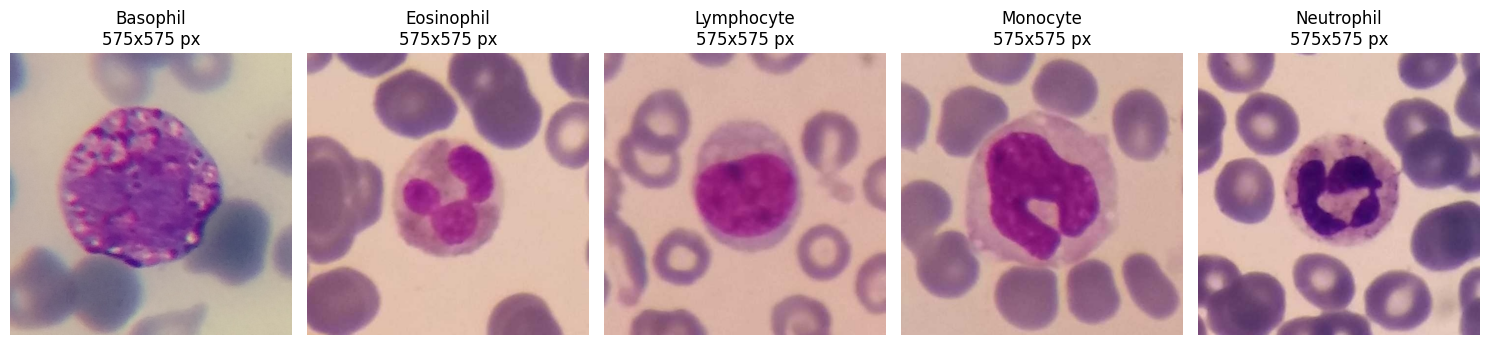

In [7]:
SAMPLE_DIR = Path(tempfile.mkdtemp()) / "samples"
for _class_name in CLASS_NAMES:
    (SAMPLE_DIR / _class_name).mkdir(parents=True, exist_ok=True)
    (SAMPLE_DIR / _class_name / f"{_class_name.lower()}.jpg").write_bytes(
        base64.b64decode(SAMPLE_IMAGES_B64[_class_name])
    )


def read_rgb(path):
    image = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f"Could not read image: {path}")
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


samples = [(read_rgb(SAMPLE_DIR / c / f"{c.lower()}.jpg"), c) for c in CLASS_NAMES]

fig, axes = plt.subplots(1, 5, figsize=(15, 3.4))
for ax, (img, label) in zip(axes, samples):
    ax.imshow(img)
    ax.set_title(f"{label}\n{img.shape[1]}x{img.shape[0]} px")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Preprocessing

The model was trained on images passed through `PreprocessingFilters.medical_enhanced`, so
inference must use the same filter. Skipping it hurts accuracy. The odd colours (green red
cells, pale background) are expected: the filter stretches contrast for the network, not for
human eyes.

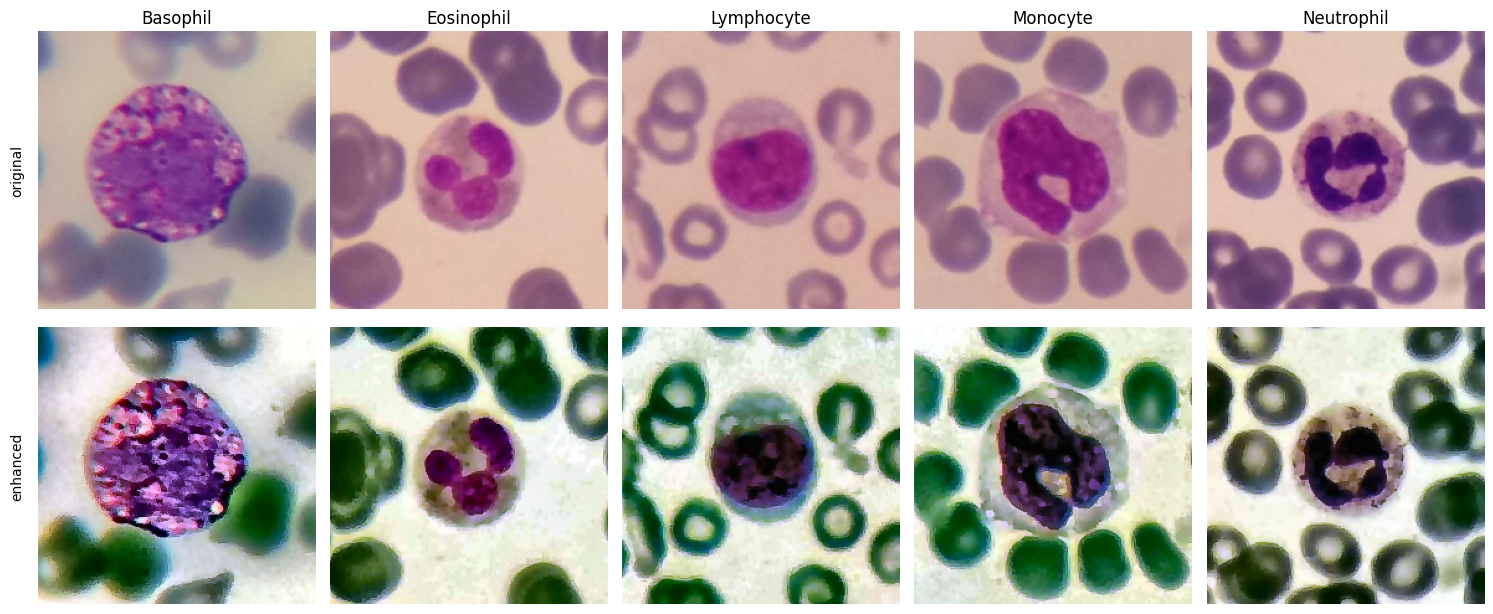

In [8]:
def preprocess(image_rgb):
    """uint8 RGB image of any size -> float32 [0, 1] array of shape (224, 224, 3)."""
    resized = cv2.resize(image_rgb, (IMG_SIZE, IMG_SIZE))
    return PreprocessingFilters.medical_enhanced(resized)


fig, axes = plt.subplots(2, 5, figsize=(15, 6.4))
for col, (img, label) in enumerate(samples):
    axes[0, col].imshow(cv2.resize(img, (IMG_SIZE, IMG_SIZE)))
    axes[0, col].set_title(label)
    axes[1, col].imshow(preprocess(img))
    for row in (0, 1):
        axes[row, col].axis("off")
axes[0, 0].text(-0.05, 0.5, "original", transform=axes[0, 0].transAxes, rotation=90, ha="right", va="center")
axes[1, 0].text(-0.05, 0.5, "enhanced", transform=axes[1, 0].transAxes, rotation=90, ha="right", va="center")
plt.tight_layout()
plt.show()

## 4. Predict

`predict_probabilities` returns an `(N, 5)` array of class probabilities ordered as
`CLASS_NAMES`. `tta=True` averages 8 deterministic flips, rotations and brightness
shifts: slower, slightly more stable.

In [9]:
def _main_head(raw):
    """The model has two heads; return the 5-class one as a float32 array."""
    if isinstance(raw, dict):
        raw = raw["main_out"] if "main_out" in raw else next(iter(raw.values()))
    elif isinstance(raw, (list, tuple)):
        raw = raw[0]
    return np.asarray(raw, dtype=np.float32)


def tta_variants(x):
    return np.stack([
        x, np.fliplr(x), np.flipud(x),
        np.rot90(x, 1), np.rot90(x, 2), np.rot90(x, 3),
        np.clip(x * 1.1, 0.0, 1.0), np.clip(x * 0.9, 0.0, 1.0),
    ]).astype(np.float32)


def predict_probabilities(processed, tta=False, batch_size=32):
    """processed: float32 array (N, 224, 224, 3) from preprocess(). Returns (N, 5)."""
    processed = np.asarray(processed, dtype=np.float32)
    if not tta:
        return _main_head(model.predict(processed, batch_size=batch_size, verbose=0))
    return np.stack([
        _main_head(model.predict(tta_variants(x), verbose=0)).mean(axis=0) for x in processed
    ])


def classify(image_rgb, tta=False):
    probs = predict_probabilities(preprocess(image_rgb)[None], tta=tta)[0]
    top = int(np.argmax(probs))
    return CLASS_NAMES[top], float(probs[top]), probs


rows = []
for img, true_label in samples:
    pred, conf, probs = classify(img)
    rows.append({"true": true_label, "predicted": pred, "confidence": round(conf, 4),
                 "correct": pred == true_label, **{c: round(float(p), 4) for c, p in zip(CLASS_NAMES, probs)}})
pd.DataFrame(rows)

,true,predicted,confidence,correct,Basophil,Eosinophil,Lymphocyte,Monocyte,Neutrophil
0,Basophil,Basophil,0.9797,True,0.9797,0.0075,0.0044,0.0046,0.0038
1,Eosinophil,Eosinophil,0.9465,True,0.0188,0.9465,0.0080,0.0190,0.0077
2,Lymphocyte,Lymphocyte,0.5744,True,0.0361,0.0609,0.5744,0.3189,0.0098
3,Monocyte,Monocyte,0.9865,True,0.0009,0.0007,0.0105,0.9865,0.0014
4,Neutrophil,Neutrophil,0.9138,True,0.0165,0.0300,0.0146,0.0250,0.9138


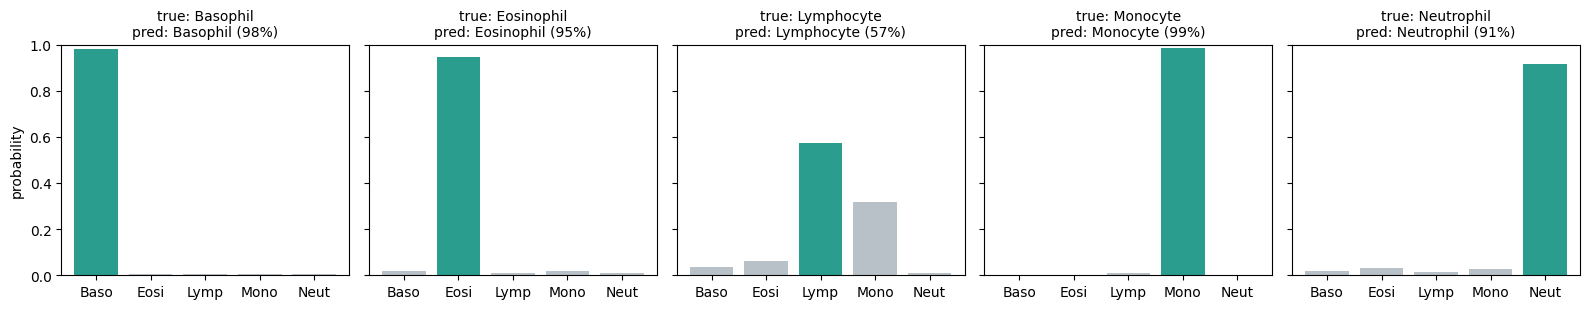

In [10]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.2), sharey=True)
for ax, (img, true_label) in zip(axes, samples):
    pred, conf, probs = classify(img)
    ax.bar(range(5), probs, color=["#2a9d8f" if i == int(np.argmax(probs)) else "#b8c0c8" for i in range(5)])
    ax.set_xticks(range(5), [c[:4] for c in CLASS_NAMES])
    ax.set_title(f"true: {true_label}\npred: {pred} ({conf:.0%})", fontsize=10)
    ax.set_ylim(0, 1)
axes[0].set_ylabel("probability")
plt.tight_layout()
plt.show()

## 5. Why did it predict that? (Grad-CAM)

Guided Grad-CAM on the last spatial `Conv2D` layer, masked to the cell so background
staining does not dominate the picture. A sound prediction highlights the nucleus or
granules, not the surrounding red cells.

The map comes from a 7x7 feature grid, so it is coarse and can spill onto neighbouring red
cells. Use it to sanity-check a prediction, not as proof of one.

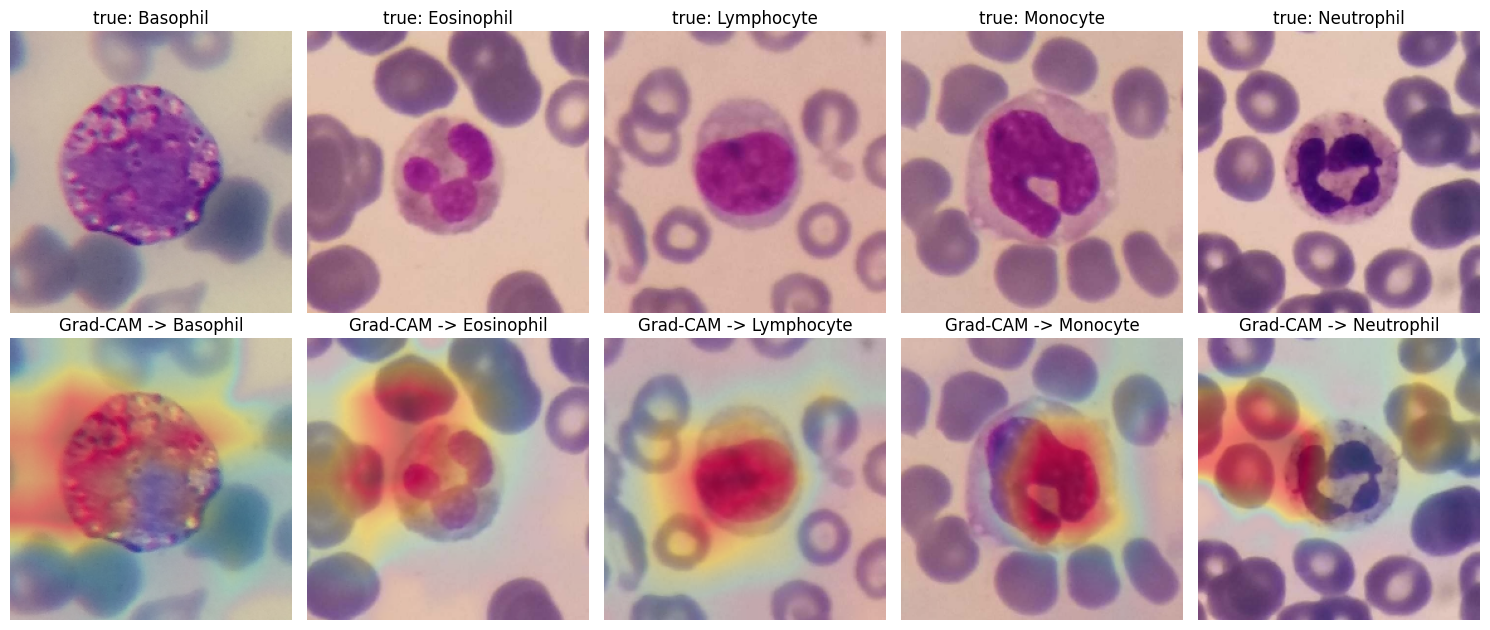

In [11]:
def _last_spatial_conv_name():
    for layer in reversed(model.layers):
        if isinstance(layer, keras.layers.Conv2D):
            shape = layer.output.shape
            if len(shape) == 4 and shape[1] and shape[2] and shape[1] > 1 and shape[2] > 1:
                return layer.name
    raise RuntimeError("No spatial Conv2D layer found for Grad-CAM.")


GRADCAM_LAYER = _last_spatial_conv_name()
_grad_model = keras.Model(
    inputs=model.inputs,
    outputs=[model.get_layer(GRADCAM_LAYER).output, model.get_layer("main_out").output],
)


def gradcam_overlay(image_rgb, class_index=None, alpha=0.45):
    """Return (overlay_rgb_uint8, predicted_index). Heatmap is None-safe: falls back to the plain image."""
    x = tf.convert_to_tensor(preprocess(image_rgb)[None], dtype=tf.float32)
    with tf.GradientTape() as tape:
        conv_out, preds = _grad_model(x, training=False)
        preds = tf.cast(preds, tf.float32)
        if class_index is None:
            class_index = int(tf.argmax(preds[0]))
        score = preds[:, class_index]
    grads = tape.gradient(score, conv_out)

    base = cv2.resize(image_rgb, (IMG_SIZE, IMG_SIZE))
    if grads is None:
        return base, class_index

    conv_out = tf.cast(conv_out[0], tf.float32)
    grads = tf.cast(grads[0], tf.float32)
    guided = tf.cast(conv_out > 0, tf.float32) * tf.cast(grads > 0, tf.float32) * grads
    weights = tf.reduce_mean(guided, axis=(0, 1))
    cam = tf.nn.relu(tf.reduce_sum(conv_out * weights, axis=-1)).numpy()
    if cam.max() <= 0:
        return base, class_index

    cam = cv2.GaussianBlur(cv2.resize(cam / cam.max(), (IMG_SIZE, IMG_SIZE)), (0, 0), sigmaX=2.0)
    mask = PreprocessingFilters.estimate_foreground_mask(base)
    cam = cam * (0.05 + 0.95 * mask)
    cam = cam / (cam.max() + 1e-8)

    heat = cv2.cvtColor(cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB)
    strength = (alpha * np.clip(cam, 0, 1))[..., None]
    overlay = (base.astype(np.float32) * (1 - strength) + heat.astype(np.float32) * strength).astype(np.uint8)
    return overlay, class_index


fig, axes = plt.subplots(2, 5, figsize=(15, 6.4))
for col, (img, true_label) in enumerate(samples):
    overlay, idx = gradcam_overlay(img)
    axes[0, col].imshow(cv2.resize(img, (IMG_SIZE, IMG_SIZE)))
    axes[0, col].set_title(f"true: {true_label}")
    axes[1, col].imshow(overlay)
    axes[1, col].set_title(f"Grad-CAM -> {CLASS_NAMES[idx]}")
    for row in (0, 1):
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()

## 6. Classify your own images

Point `IMAGE_DIR` at any folder of images (searched recursively). On Kaggle that is usually
`/kaggle/input/<your-dataset>/...`. By default it runs on the bundled samples so this cell
works out of the box. Results are written to `predictions.csv`.

In [12]:
IMAGE_DIR = SAMPLE_DIR          # <- change me, e.g. Path("/kaggle/input/my-smears")
USE_TTA = False
OUTPUT_CSV = Path("/kaggle/working/predictions.csv") if Path("/kaggle/working").is_dir() else Path("predictions.csv")

def predict_folder(folder, tta=False, batch_size=32):
    paths = sorted(p for p in Path(folder).rglob("*") if p.suffix.lower() in IMAGE_EXTENSIONS)
    if not paths:
        raise FileNotFoundError(f"No images found under {folder}")

    records = []
    for start in range(0, len(paths), batch_size):
        chunk, batch = [], []
        for path in paths[start:start + batch_size]:
            try:
                batch.append(preprocess(read_rgb(path)))
                chunk.append(path)
            except ValueError as err:
                print("skipped:", err)
        if not batch:
            continue
        probs = predict_probabilities(np.stack(batch), tta=tta)
        for path, p in zip(chunk, probs):
            top = int(np.argmax(p))
            records.append({"file": str(path), "predicted": CLASS_NAMES[top], "confidence": float(p[top]),
                            **{f"prob_{c}": float(v) for c, v in zip(CLASS_NAMES, p)}})
    return pd.DataFrame(records)


predictions = predict_folder(IMAGE_DIR, tta=USE_TTA)
predictions.to_csv(OUTPUT_CSV, index=False)
print(f"{len(predictions)} images -> {OUTPUT_CSV}")
predictions[["file", "predicted", "confidence"]].assign(
    file=lambda d: d["file"].str.replace(str(IMAGE_DIR), "", regex=False)
).round(4)

5 images -> /kaggle/working/predictions.csv


,file,predicted,confidence
0,/Basophil/basophil.jpg,Basophil,0.9797
1,/Eosinophil/eosinophil.jpg,Eosinophil,0.9465
2,/Lymphocyte/lymphocyte.jpg,Lymphocyte,0.5744
3,/Monocyte/monocyte.jpg,Monocyte,0.9865
4,/Neutrophil/neutrophil.jpg,Neutrophil,0.9138


## 7. Optional: evaluate on Raabin-WBC TestA / TestB

Attach the Raabin-WBC dataset (folders `Train/`, `TestA/`, `TestB/`, each with one subfolder
per class) and this section finds it automatically. It evaluates a random `SAMPLE_FRACTION`
of each split, keeping the original class proportions so the numbers stay comparable to the
full-split results above. Set `SAMPLE_FRACTION = None` to use everything.

| Switch | What it does | Paper protocol |
| :-- | :-- | :-- |
| `USE_REINHARD` | match each image's LAB statistics to the Train set | on |
| `TESTB_BINARY_ROUTING` | TestB has only Lymphocyte and Neutrophil, so pick between those two | on |
| `USE_TTA_EVAL` | 8x test-time augmentation | on (slow without a GPU) |

Turn `USE_REINHARD` and `TESTB_BINARY_ROUTING` off to see the single-pass baseline. The gap
on TestB is the domain-shift story from the paper.

In [13]:
SAMPLE_FRACTION = 0.15    # share of each class to evaluate; None = every image
USE_REINHARD = True
TESTB_BINARY_ROUTING = True
USE_TTA_EVAL = False
SEED = 42


def find_raabin_root():
    explicit = os.environ.get("WBC_DATA_ROOT")
    roots = [explicit] if explicit else []
    roots += ["/kaggle/input", "data/raabin-wbc-data", "../data/raabin-wbc-data"]
    for root in roots:
        if not root or not os.path.isdir(root):
            continue
        base_depth = root.rstrip(os.sep).count(os.sep)
        for current, dirs, _ in os.walk(root):
            if current.count(os.sep) - base_depth >= 5:
                dirs[:] = []
                continue
            if "TestA" in dirs and "TestB" in dirs:
                return Path(current)
    return None


def collect(split_dir, fraction, seed=SEED):
    rng = np.random.default_rng(seed)
    items = []
    for class_name in CLASS_NAMES:
        class_dir = Path(split_dir) / class_name
        if not class_dir.is_dir():
            continue
        files = sorted(p for p in class_dir.iterdir() if p.suffix.lower() in IMAGE_EXTENSIONS)
        if fraction is not None and files:
            keep = max(1, round(len(files) * fraction))
            files = [files[i] for i in sorted(rng.choice(len(files), keep, replace=False))]
        items += [(p, MAIN_IDX[class_name]) for p in files]
    return items


def estimate_reinhard_reference(train_dir, fraction=0.12, seed=SEED):
    # ~1,200 Train images, as in the paper's evaluation script
    items = collect(train_dir, fraction=fraction, seed=seed)
    means, stds = [], []
    for path, _ in items:
        lab = cv2.cvtColor(cv2.resize(read_rgb(path), (IMG_SIZE, IMG_SIZE)), cv2.COLOR_RGB2LAB).astype(np.float32)
        means.append(lab.mean(axis=(0, 1)))
        stds.append(lab.std(axis=(0, 1)) + 1e-6)
    return np.mean(means, axis=0), np.mean(stds, axis=0)


def reinhard(image_rgb, target_mean, target_std):
    lab = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2LAB).astype(np.float32)
    norm = (lab - lab.mean(axis=(0, 1))) / (lab.std(axis=(0, 1)) + 1e-6)
    norm = np.clip(norm * target_std + target_mean, 0, 255).astype(np.uint8)
    return cv2.cvtColor(norm, cv2.COLOR_LAB2RGB)


def evaluate_split(split_dir, ref, route_binary):
    items = collect(split_dir, SAMPLE_FRACTION)
    batch, y_true = [], []
    for path, label in items:
        image = cv2.resize(read_rgb(path), (IMG_SIZE, IMG_SIZE))
        if ref is not None:
            image = reinhard(image, *ref)
        batch.append(PreprocessingFilters.medical_enhanced(image))
        y_true.append(label)
    probs = predict_probabilities(np.stack(batch), tta=USE_TTA_EVAL)
    if route_binary:
        keep = [MAIN_IDX["Lymphocyte"], MAIN_IDX["Neutrophil"]]
        y_pred = np.array(keep)[np.argmax(probs[:, keep], axis=1)]
    else:
        y_pred = np.argmax(probs, axis=1)
    return np.array(y_true), y_pred


RAABIN_ROOT = find_raabin_root()
if RAABIN_ROOT is None:
    print("Raabin-WBC not found. Attach it via 'Add Input' (or set WBC_DATA_ROOT) to run this section.")
else:
    from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

    print("Dataset:", RAABIN_ROOT)
    ref = estimate_reinhard_reference(RAABIN_ROOT / "Train") if USE_REINHARD else None
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for ax, split in zip(axes, ("TestA", "TestB")):
        y_true, y_pred = evaluate_split(RAABIN_ROOT / split, ref, route_binary=(split == "TestB" and TESTB_BINARY_ROUTING))
        present = sorted(set(y_true) | set(y_pred))
        print(f"\n===== {split}: n={len(y_true)}, accuracy={accuracy_score(y_true, y_pred):.4f} =====")
        print(classification_report(y_true, y_pred, labels=present,
                                    target_names=[CLASS_NAMES[i] for i in present], zero_division=0, digits=4))
        cm = confusion_matrix(y_true, y_pred, labels=range(5))
        ax.imshow(cm, cmap="Blues")
        ax.set(xticks=range(5), yticks=range(5), xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
               xlabel="predicted", ylabel="true", title=f"{split} (n={len(y_true)})")
        plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
        for (r, c), v in np.ndenumerate(cm):
            ax.text(c, r, v, ha="center", va="center", color="white" if v > cm.max() / 2 else "black")
    plt.tight_layout()
    plt.show()

Raabin-WBC not found. Attach it via 'Add Input' (or set WBC_DATA_ROOT) to run this section.


## Notes and limits

- **Input**: one centred leukocyte per image (Raabin-WBC style crops, Giemsa stain). It does not
  detect or segment cells in a full field of view.
- **Classes**: five normal leukocyte types only. Blasts, band cells, artefacts and anything else
  will still be forced into one of the five.
- **Domain shift**: accuracy drops on unseen cameras and stains (see TestB above). Treat low
  confidence as a signal to review manually.
- **Keras versions**: the loader handles models saved by Keras 3.14 on older Keras 3.x. If loading
  still fails, run `pip install -U keras tensorflow` and restart the kernel.

## Citation

```bibtex
@article{yildirim2026wbc,
  title={Achieving Robust Out-of-Distribution Generalization in Peripheral Blood Smears via Custom
         Attention Mechanisms, Medical Enhanced Filtering, and Inference-Time Domain Adaptation},
  author={Yildirim, Emirhan},
  doi={10.13140/RG.2.2.34201.79208},
  year={2026}
}
```

The sample images and test splits come from Raabin-WBC (Kouzehkanan et al., *Scientific Reports*
12, 1123, 2022). Please cite it too and check its license before redistributing the data.
Code and model are released under Apache-2.0.